# Salario mínimo en términos reales

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "smi-real"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Salario mínimo en términos reales"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "Dólares PPA a precios constantes de 2025"  # incluye deflactor/PPA si aplica (METODOLOGIA §2.4)
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 0  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El salario mínimo legal anual, descontada la inflación y en dólares con la misma capacidad de compra en todos los países (paridad de poder adquisitivo, PPA).

**Cómo se lee.** Muestra cuánto puede comprar el salario mínimo de cada país a lo largo del tiempo. En España es el salario mínimo interprofesional (SMI) anual, que se paga en catorce pagas.

**Limitaciones.**
- En EE. UU. se usa el salario mínimo federal; muchos estados y ciudades tienen un mínimo más alto.
- Cuando el salario mínimo cambia a mitad de año, la OCDE usa una media del año o el valor de una fecha de referencia, según el país.
- La OCDE no publica los agregados de la UE-27 ni de la OCDE.

## 2. Descarga

- **España, EE. UU. y Canadá:** OCDE, *Real minimum wages* (`OECD.ELS.SAE,DSD_EARNINGS@RMW`, versión 1.0): salario mínimo (`SM_WG`) anual (`A`) en dólares PPA (`USD_PPP`) a precios constantes (`Q`), con el año de referencia de la última edición (`BASE_PER`, comprobado en el código).
- **UE-27 y OCDE:** sin dato; la fuente no publica los agregados.
- **Solo para las notas:** OCDE, salario mínimo en euros corrientes (`DSD_EARNINGS@MW_CURP`), anual y mensual, para comprobar que el dato de España es el SMI anual de catorce pagas.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

import io
from datetime import date

import requests

from lib._http import pedir
from lib import eurostat, oecd
from lib.tipos import FuenteMeta

HOY = date.today().isoformat()

AREAS = {"ESP": "espana", "USA": "eeuu", "CAN": "canada", "OECD": "ocde", "EU27_2020": "ue27"}
DATAFLOW = "OECD.ELS.SAE,DSD_EARNINGS@RMW,1.0"
# Dimensiones: país . medida . unidad . periodo de pago (A: anual) . precios (Q: constantes) . operación . sexo
CLAVE = "{AREA}.SM_WG.USD_PPP.A.Q._Z._Z"
DATAFLOW_CURP = "OECD.ELS.SAE,DSD_EARNINGS@MW_CURP,1.0"

oc, fuentes_oc = oecd.get(DATAFLOW, CLAVE, areas=AREAS, desde=DESDE)
# Solo para las notas: SMI de España en euros corrientes, anual y mensual
anual, _ = oecd.get(DATAFLOW_CURP, "{AREA}.SM_WG.EUR.A.V._Z._Z", areas={"ESP": "espana"}, desde=DESDE)
mensual, _ = oecd.get(DATAFLOW_CURP, "{AREA}.SM_WG.EUR.M.V._Z._Z", areas={"ESP": "espana"}, desde=DESDE)
print(oc.groupby("serie")["periodo"].agg(["min", "max", "count"]))


def metadatos(dataflow, clave, areas):
    """SDMX-CSV completo de la OCDE (con BASE_PER y OBS_STATUS), que `oecd.get` no devuelve."""
    r = pedir(
        requests.Session(), f"{oecd.BASE}/{dataflow}/{clave.replace('{AREA}', '+'.join(areas))}", {"startPeriod": str(DESDE)},
        error_cls=oecd.OecdError, etiqueta="metadatos", mensaje=lambda r: r.text[:200], headers=oecd.CABECERA_CSV,
    )
    return pd.read_csv(io.StringIO(r.text), dtype=str)


meta = metadatos(DATAFLOW, CLAVE, AREAS)
ANIO_BASE = sorted(meta["BASE_PER"].dropna().unique())
print("Año de referencia de los precios constantes:", ANIO_BASE)

         min   max  count
serie                    
canada  1976  2025     50
eeuu    1976  2025     50
espana  1976  2025     50


Año de referencia de los precios constantes: ['2025']


## 3. Transformación

1. La serie se usa tal como la publica la OCDE (ya está deflactada y en PPA). Se comprueba que el año de referencia es el que dice `UNIDAD`.
2. **Comprobación del SMI de España:** el salario mínimo anual en euros corrientes de la OCDE entre catorce da el SMI mensual de los reales decretos; se calcula para el último año y se anota (la comprobación con el BOE queda en `pending.md`). La serie mensual de la OCDE es el anual entre doce.
3. La UE-27 y la OCDE quedan sin dato, con la fuente consultada.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"].dropna()  # noqa: E731


def comparar(a, b):
    """Años comunes de dos series y diferencia absoluta entre ellas, en puntos."""
    comunes = sorted(set(a.index) & set(b.index))
    return comunes, (a[comunes] - b[comunes]).abs()


def nota_comparacion(texto, a, b, d=2):
    comunes, dif = comparar(a, b)
    return (f"{texto}: en los {len(comunes)} años comunes ({comunes[0]}-{comunes[-1]}), la diferencia máxima es de "
            f"{es(dif.max(), d)} puntos, en {int(dif.idxmax())}.")


def anadir_sin_dato(df, fuentes, sin_dato):
    """Añade las series de la cesta sin dato comparable (todo `null`) con la fuente consultada."""
    vacias = pd.DataFrame({"serie": list(sin_dato), "periodo": DESDE, "valor": float("nan")})
    extra = [FuenteMeta(s, org, cod, url, HOY) for s, (org, cod, url) in sin_dato.items()]
    return pd.concat([df, vacias], ignore_index=True), [*fuentes, *extra]


assert ANIO_BASE == ["2025"], "El año de referencia ya no es 2025: actualiza UNIDAD y las notas"
SIN = (oecd.ORGANISMO, "DSD_EARNINGS@RMW: la OCDE no publica el agregado", oecd.URL_EXPLORER)
df, fuentes = anadir_sin_dato(oc, fuentes_oc, {s: SIN for s in ["ue27", "ocde"] if s not in set(oc["serie"])})

a, m = serie(anual, "espana"), serie(mensual, "espana")
comunes = sorted(set(a.index) & set(m.index))
assert ((a[comunes] / m[comunes] - 12).abs() < 0.01).all(), "La serie mensual de la OCDE ya no es el anual entre doce"
ULTIMO = int(a.index.max())
NOTAS = [
    "OCDE, salarios mínimos reales (DSD_EARNINGS@RMW): salario mínimo legal anual en dólares PPA a precios constantes "
    f"de {ANIO_BASE[0]}.",
    f"España: es el salario mínimo interprofesional anual. En {ULTIMO}, la OCDE da {es(a[ULTIMO], 0)} euros corrientes "
    f"al año (DSD_EARNINGS@MW_CURP), que en catorce pagas son {es(a[ULTIMO] / 14, 2)} euros al mes.",
    "EE. UU.: salario mínimo federal; muchos estados y ciudades tienen un salario mínimo más alto.",
    "UE-27 y OCDE: la fuente no publica los agregados y las series quedan vacías.",
]
for n in NOTAS:
    print("-", n)
display(pd.DataFrame({"anual (EUR)": a, "anual / 14": a / 14}).tail(8).round(2))

- OCDE, salarios mínimos reales (DSD_EARNINGS@RMW): salario mínimo legal anual en dólares PPA a precios constantes de 2025.
- España: es el salario mínimo interprofesional anual. En 2025, la OCDE da 16.576 euros corrientes al año (DSD_EARNINGS@MW_CURP), que en catorce pagas son 1184,00 euros al mes.
- EE. UU.: salario mínimo federal; muchos estados y ciudades tienen un salario mínimo más alto.
- UE-27 y OCDE: la fuente no publica los agregados y las series quedan vacías.


,anual (EUR),anual / 14
periodo,,
2018,10302.6,735.9
2019,12600.0,900.0
2020,13300.0,950.0
2021,13300.0,950.0
2022,14000.0,1000.0
2023,15120.0,1080.0
2024,15876.0,1134.0
2025,16576.0,1184.0


## 4. Visualización

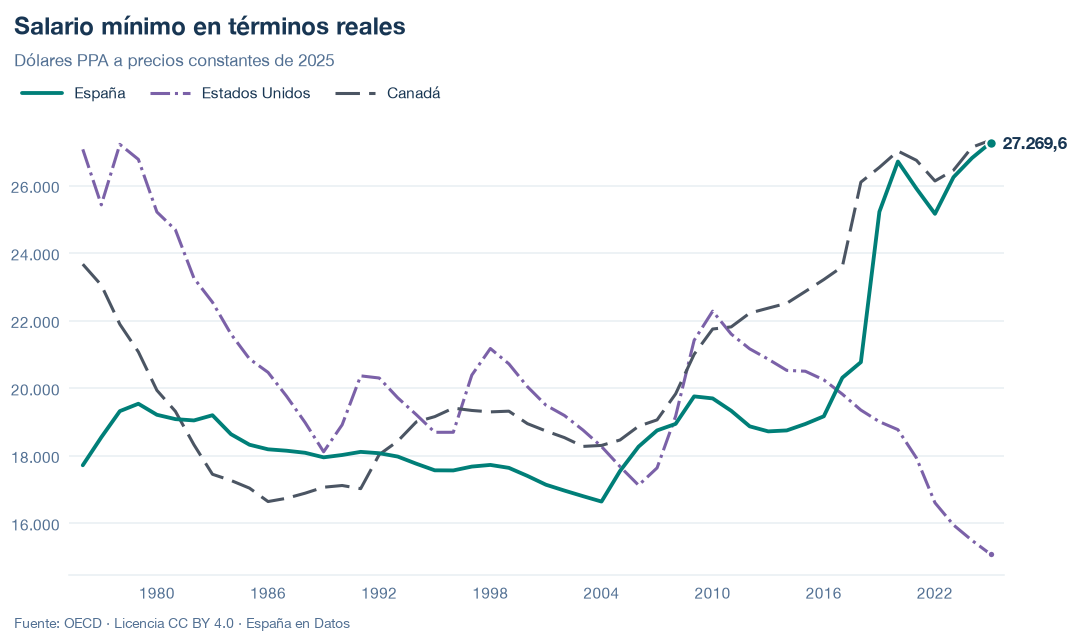

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/smi-real.json y data/smi-real.csv


## 6. Fuentes, notas y licencia

- OCDE, salarios mínimos reales: `OECD.ELS.SAE,DSD_EARNINGS@RMW,1.0` (`SM_WG`, `USD_PPP`, `A`, `Q`).
- OCDE, salarios mínimos a precios corrientes: `OECD.ELS.SAE,DSD_EARNINGS@MW_CURP,1.0` (`SM_WG`, `EUR`, `A` y `M`, `V`; solo para las notas).

La fecha de consulta de cada serie está en `fuentes` del JSON.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.